# Notebook 02 — Regresión reproducible sobre Airfoil

**Problema 6.** Predecir el nivel de presión sonora `sonido` (dB) a partir de `frecuencia`, `angulo`, `cuerda`, `velocidad` y `espesor`.

Flujo del notebook:

1. Auditoría de los datos crudos.
2. Partición 80/20.
3. EDA solo sobre el conjunto de desarrollo.
4. Validación cruzada de 5 pliegues para elegir representación y regularización.
5. Una única evaluación final en prueba.

Los modelos OLS, Ridge y Lasso son las implementaciones propias de `modelos.py`.

In [1]:
import hashlib
import json
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, KFold
from sklearn.preprocessing import StandardScaler

from modelos import SEMILLA, LassoProximal, RegresionOLS, RegresionRidge

DATA = Path("data")
RESULTADOS = Path("resultados")
PARAMETROS = RESULTADOS / "parametros"
PARAMETROS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 6a. Datos crudos, auditoría y partición

### Carga

El archivo se descarga del UCI Machine Learning Repository, con la misma fuente del notebook de regresión de clase, solo si no existe en `data/`. El archivo crudo no se modifica.

Cada fila recibe un `id` estable: su número de línea en el archivo (1 a 1503). Se registra el hash SHA-256 del archivo para comprobar que los `id` siempre se refieren al mismo contenido.

In [2]:
# Reutilizado de clase: descarga del ZIP de UCI y lectura con los nombres de columnas.
# Mejoras: id estable por número de línea y hash SHA-256 del archivo crudo.
RUTA = DATA / "airfoil_self_noise.dat"
URL = "https://archive.ics.uci.edu/static/public/291/airfoil+self+noise.zip"
if not RUTA.exists():
    DATA.mkdir(exist_ok=True)
    with urlopen(URL, timeout=60) as respuesta:
        with ZipFile(BytesIO(respuesta.read())) as z:
            RUTA.write_bytes(z.read(next(n for n in z.namelist() if Path(n).name == RUTA.name)))

VARIABLES = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor"]
OBJETIVO = "sonido"
crudo = pd.read_csv(RUTA, sep=r"\s+", header=None, names=VARIABLES + [OBJETIVO])
crudo.insert(0, "id", np.arange(1, len(crudo) + 1))      # número de línea en el archivo

sha256 = hashlib.sha256(RUTA.read_bytes()).hexdigest()
print(f"{RUTA}: {crudo.shape[0]} filas x {crudo.shape[1] - 1} columnas | SHA-256 {sha256[:16]}...")
crudo.head()

data\airfoil_self_noise.dat: 1503 filas x 6 columnas | SHA-256 74c75fd71783f1e6...


,id,frecuencia,angulo,cuerda,velocidad,espesor,sonido
0,1,800,0.0,0.3048,71.3,0.0027,126.201
1,2,1000,0.0,0.3048,71.3,0.0027,125.201
2,3,1250,0.0,0.3048,71.3,0.0027,125.951
3,4,1600,0.0,0.3048,71.3,0.0027,127.591
4,5,2000,0.0,0.3048,71.3,0.0027,127.461


### Auditoría de formato, identidad y dominios

Las unidades vienen de la documentación de UCI. Las reglas de dominio son físicas y deterministas: no usan estadísticas de los datos.

| Variable | Descripción | Unidad | Regla de dominio |
|---|---|---|---|
| `frecuencia` | Frecuencia | Hz | $> 0$ |
| `angulo` | Ángulo de ataque | grados | $0 \le \alpha < 90$ |
| `cuerda` | Longitud de la cuerda del perfil | m | $> 0$ |
| `velocidad` | Velocidad del flujo libre | m/s | $> 0$ |
| `espesor` | Espesor de desplazamiento del lado de succión | m | $> 0$ |
| `sonido` | Nivel de presión sonora escalado | dB | finito |

In [3]:
reglas = {
    "frecuencia": crudo["frecuencia"] > 0,
    "angulo":     crudo["angulo"].between(0, 90, inclusive="left"),
    "cuerda":     crudo["cuerda"] > 0,
    "velocidad":  crudo["velocidad"] > 0,
    "espesor":    crudo["espesor"] > 0,
    "sonido":     np.isfinite(crudo["sonido"]),
}
unidades = {"frecuencia": "Hz", "angulo": "grados", "cuerda": "m", "velocidad": "m/s",
            "espesor": "m", "sonido": "dB"}

auditoria = pd.DataFrame({
    "tipo": crudo[VARIABLES + [OBJETIVO]].dtypes.astype(str),
    "unidad": pd.Series(unidades),
    "faltantes": crudo[VARIABLES + [OBJETIVO]].isna().sum(),
    "valores únicos": crudo[VARIABLES + [OBJETIVO]].nunique(),
    "mínimo": crudo[VARIABLES + [OBJETIVO]].min(),
    "máximo": crudo[VARIABLES + [OBJETIVO]].max(),
    "fuera de dominio": pd.Series({v: int((~r).sum()) for v, r in reglas.items()}),
})
auditoria.to_csv(RESULTADOS / "p6_auditoria.csv")

n_dup_filas = int(crudo.duplicated(subset=VARIABLES + [OBJETIVO]).sum())
n_dup_condiciones = int(crudo.duplicated(subset=VARIABLES).sum())
print("Filas duplicadas exactas (5 variables + sonido):", n_dup_filas)
print("Condiciones experimentales repetidas (solo las 5 variables):", n_dup_condiciones)
print("Ids únicos:", crudo["id"].is_unique)
auditoria

Filas duplicadas exactas (5 variables + sonido): 0
Condiciones experimentales repetidas (solo las 5 variables): 0
Ids únicos: True


,tipo,unidad,faltantes,valores únicos,mínimo,máximo,fuera de dominio
frecuencia,int64,Hz,0,21,200.0000,20000.0000,0
angulo,float64,grados,0,27,0.0000,22.2000,0
cuerda,float64,m,0,6,0.0254,0.3048,0
velocidad,float64,m/s,0,4,31.7000,71.3000,0
espesor,float64,m,0,105,0.0004,0.0584,0
sonido,float64,dB,0,1456,103.3800,140.9870,0


**Resultado de la auditoría.**

- Todas las columnas son numéricas, sin faltantes y dentro de su dominio físico.
- No hay filas duplicadas ni condiciones experimentales repetidas.
- No hace falta ninguna regla de limpieza: se conservan las 1503 filas.
- Varias variables toman pocos valores, porque el experimento usa niveles discretos: 4 velocidades, 6 cuerdas, 21 frecuencias y 27 ángulos.

### Partición 80/20

- La partición se hace con `GroupShuffleSplit` (semilla 2026). El grupo de cada fila identifica las filas idénticas, de modo que un duplicado exacto nunca podría quedar repartido entre desarrollo y prueba. Aquí no hay duplicados, así que cada grupo es una fila.
- En el mismo paso se asignan los 5 pliegues de validación cruzada dentro de desarrollo (`KFold` con mezcla y semilla 2026).
- El manifiesto `p6_particiones.csv` guarda el conjunto y el pliegue de cada `id`.

In [4]:
grupos = crudo.groupby(VARIABLES + [OBJETIVO]).ngroup()      # filas idénticas -> mismo grupo
idx_des, idx_pru = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
                        .split(crudo, groups=grupos))
desarrollo = crudo.iloc[idx_des].reset_index(drop=True)
prueba = crudo.iloc[idx_pru].reset_index(drop=True)
assert set(grupos.iloc[idx_des]).isdisjoint(grupos.iloc[idx_pru])

# Pliegues de validación cruzada dentro de desarrollo, fijos para todos los candidatos.
pliegues = list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(desarrollo))

manifiesto = pd.concat([desarrollo[["id"]].assign(conjunto="desarrollo"),
                        prueba[["id"]].assign(conjunto="prueba")]).set_index("id")
manifiesto["pliegue_validacion"] = pd.NA
for k, (_, idx_val) in enumerate(pliegues, start=1):
    manifiesto.loc[desarrollo["id"].iloc[idx_val], "pliegue_validacion"] = k
manifiesto.sort_index().to_csv(RESULTADOS / "p6_particiones.csv")

print(f"Desarrollo: {len(desarrollo)} filas | Prueba: {len(prueba)} filas")
print("Filas por pliegue de validación:", [len(v) for _, v in pliegues])

Desarrollo: 1202 filas | Prueba: 301 filas
Filas por pliegue de validación: [241, 241, 240, 240, 240]


### EDA sobre el conjunto de desarrollo

A partir de aquí todo el análisis exploratorio usa solo las 1202 filas de desarrollo. Las hipótesis se formularon antes de mirar las gráficas:

- **H1 (univariada).** `frecuencia` y `espesor` tienen una cola derecha fuerte, porque varían en más de un orden de magnitud. En acústica la frecuencia se analiza en escala logarítmica (bandas de octava).
- **H2 (asociación).** El sonido no depende de la frecuencia de forma monótona. Según el modelo semiempírico de Brooks, Pope y Marcolini, del que provienen estos ensayos, el espectro de ruido se organiza por el número de Strouhal $St = f\,\delta/U$ (frecuencia × espesor / velocidad), no por la frecuencia sola.
- **H3 (grupos).** A mayor velocidad del flujo, mayor nivel sonoro.

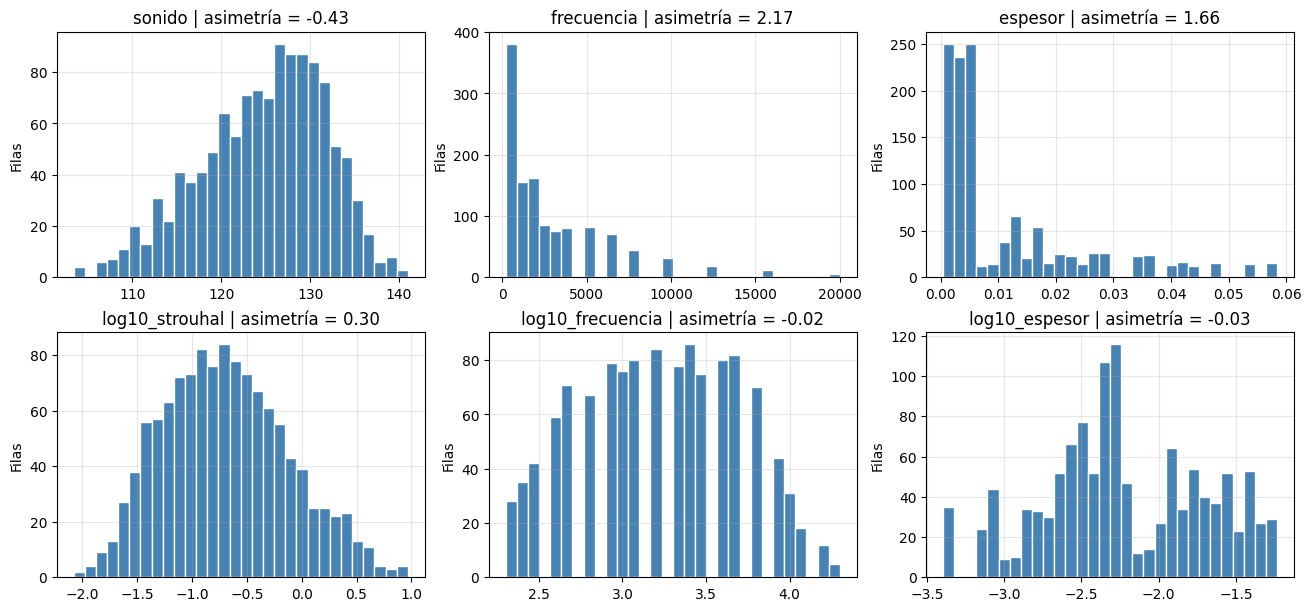

,count,mean,std,min,25%,50%,75%,max
sonido,1202.0,124.7669,7.0195,103.3800,120.1028,125.7160,130.0498,140.9870
frecuencia,1202.0,2878.3195,3170.4437,200.0000,630.0000,1600.0000,4000.0000,20000.0000
angulo,1202.0,6.8977,5.9299,0.0000,2.0000,5.4000,11.2000,22.2000
cuerda,1202.0,0.1374,0.0929,0.0254,0.0508,0.1016,0.2286,0.3048
velocidad,1202.0,51.2969,15.6537,31.7000,39.6000,55.5000,71.3000,71.3000
espesor,1202.0,0.0116,0.0135,0.0004,0.0027,0.0050,0.0161,0.0584


In [5]:
# H1: distribuciones univariadas en escala original y logarítmica.
eda = desarrollo.copy()
eda["log10_frecuencia"] = np.log10(eda["frecuencia"])
eda["log10_espesor"] = np.log10(eda["espesor"])
eda["log10_strouhal"] = np.log10(eda["frecuencia"] * eda["espesor"] / eda["velocidad"])

fig, ax = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for a, col in zip(ax.ravel(), ["sonido", "frecuencia", "espesor",
                               "log10_strouhal", "log10_frecuencia", "log10_espesor"]):
    a.hist(eda[col], bins=30, color="steelblue", edgecolor="white")
    a.set(title=f"{col} | asimetría = {eda[col].skew():.2f}", ylabel="Filas")
plt.show()

eda[["sonido"] + VARIABLES].describe().T

**H1 se confirma.** `frecuencia` (asimetría 2.17) y `espesor` (1.66) tienen cola derecha larga; en escala $\log_{10}$ su asimetría es prácticamente 0. `sonido` es aproximadamente simétrico, con una cola izquierda moderada (−0.43), así que se modela en dB sin transformarlo, como pide el enunciado. Los valores grandes de `espesor` corresponden a ángulos de ataque altos. Son condiciones experimentales válidas, así que no se eliminan aunque queden fuera de los bigotes de una caja.

,Pearson,Spearman
frecuencia,-0.402,-0.347
angulo,-0.152,-0.133
cuerda,-0.235,-0.244
velocidad,0.149,0.146
espesor,-0.323,-0.275
log10_frecuencia,-0.364,-0.347
log10_strouhal,-0.633,-0.603


,frecuencia,angulo,cuerda,velocidad,espesor
frecuencia,1.00,-0.28,0.02,0.12,-0.23
angulo,-0.28,1.00,-0.52,0.07,0.75
cuerda,0.02,-0.52,1.00,-0.03,-0.22
velocidad,0.12,0.07,-0.03,1.00,-0.02
espesor,-0.23,0.75,-0.22,-0.02,1.00


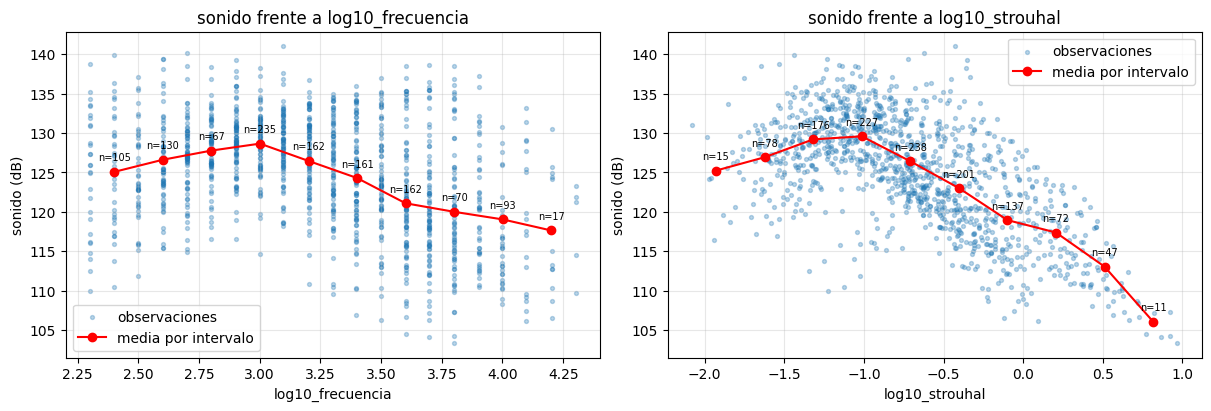

In [6]:
# H2: asociación con el sonido (Pearson = lineal, Spearman = monótona).
predictores_eda = VARIABLES + ["log10_frecuencia", "log10_strouhal"]
asociacion = pd.DataFrame({
    "Pearson": eda[predictores_eda].corrwith(eda["sonido"]),
    "Spearman": eda[predictores_eda].corrwith(eda["sonido"], method="spearman"),
})
display(asociacion.round(3))
display(eda[VARIABLES].corr().round(2))

# Medias de sonido por intervalos de log10(St), con el tamaño de cada intervalo.
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for a, col in zip(ax, ["log10_frecuencia", "log10_strouhal"]):
    intervalos = pd.cut(eda[col], 10)
    medias = eda.groupby(intervalos, observed=True)["sonido"].agg(["mean", "size"])
    centros = [i.mid for i in medias.index]
    a.scatter(eda[col], eda["sonido"], s=8, alpha=0.3, label="observaciones")
    a.plot(centros, medias["mean"], "o-", color="red", label="media por intervalo")
    for x, (m, n) in zip(centros, medias.to_numpy()):
        a.annotate(f"n={int(n)}", (x, m), textcoords="offset points", xytext=(0, 8), fontsize=7, ha="center")
    a.set(xlabel=col, ylabel="sonido (dB)", title=f"sonido frente a {col}")
    a.legend()
plt.show()

**H2 se confirma.**

- La correlación de Pearson con el sonido pasa de −0.40 (`frecuencia`) a −0.63 (`log10_strouhal`).
- Las medias por intervalo muestran una forma de U invertida en $\log_{10}St$: el sonido sube hasta $\log_{10}St\approx-1$ y después cae más de 20 dB. Una recta en las variables originales no puede representar esa curvatura.
- Con la frecuencia sola se insinúa la misma forma, pero mucho más dispersa: a una misma frecuencia el sonido varía más de 25 dB, porque se mezclan condiciones con distinto espesor y velocidad. Al dividir por $U$ y multiplicar por $\delta$, la nube se ordena.
- Entre los predictores, `angulo` y `espesor` tienen correlación 0.75: el espesor de la capa límite crece con el ángulo de ataque. Esa redundancia es un motivo para evaluar Ridge.

,n,media,mediana,desviacion,q1,q3
velocidad,,,,,,
31.7,220,123.94,124.19,6.65,119.90,128.94
39.6,373,123.45,124.49,7.24,118.21,129.29
55.5,222,125.67,126.52,6.31,121.78,130.18
71.3,387,125.99,127.05,7.13,121.31,131.28


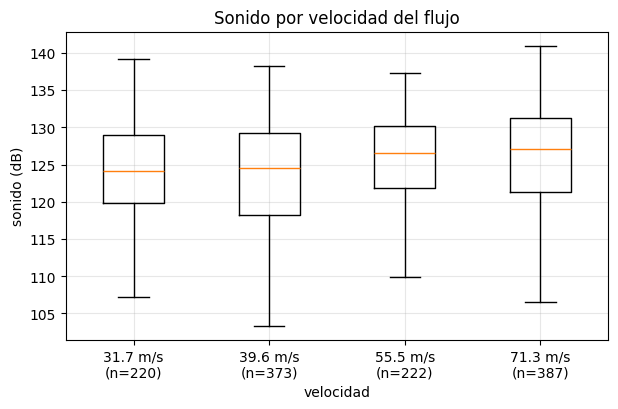

In [7]:
# H3: sonido por grupos de velocidad (4 niveles del experimento), con tamaño de grupo.
por_velocidad = eda.groupby("velocidad")["sonido"].agg(
    n="size", media="mean", mediana="median", desviacion="std",
    q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
display(por_velocidad.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([g["sonido"] for _, g in eda.groupby("velocidad")],
           tick_labels=[f"{v} m/s\n(n={n})" for v, n in por_velocidad["n"].items()])
ax.set(xlabel="velocidad", ylabel="sonido (dB)", title="Sonido por velocidad del flujo")
plt.show()

**H3 se confirma parcialmente.** La mediana sube de 124.2 dB (31.7 m/s, $n=220$) a 127.1 dB (71.3 m/s, $n=387$). Sin embargo, el aumento es pequeño frente a la dispersión dentro de cada grupo (desviación de 6 a 7 dB), y 31.7 y 39.6 m/s casi no se distinguen. La velocidad sola explica poco. Su papel es más claro dentro del número de Strouhal, donde divide a la frecuencia por el espesor.

### Registro de hallazgos y decisiones

| Hallazgo | Evidencia | Decisión | Riesgo de fuga |
|---|---|---|---|
| Sin faltantes, duplicados ni valores fuera de dominio | Auditoría (tabla anterior) | Conservar las 1503 filas; ninguna limpieza | Ninguno: la auditoría solo revisa formato y reglas físicas |
| `frecuencia` y `espesor` asimétricas (2.17 y 1.66) | Histogramas, H1 | Usarlas en escala $\log_{10}$ dentro de la variable derivada | Ninguno: el logaritmo es una función fija, sin parámetros estimados |
| El sonido se organiza por $St=f\delta/U$ con forma de U invertida | $r=-0.63$ frente a $-0.40$; medias por intervalo, H2 | Representación alternativa: agregar $\log_{10}St$ y $(\log_{10}St)^2$ | Bajo: las fórmulas son fijas; la decisión usó solo desarrollo, y la CV la evalúa con los mismos pliegues |
| `angulo` y `espesor` correlacionadas (0.75) | Matriz de correlación | Incluir Ridge y Lasso en la comparación | Ninguno |
| Efecto de la velocidad pequeño frente a la dispersión | Medianas por grupo y tamaños, H3 | Mantener `velocidad` como numérica (4 niveles ordenados) | Ninguno |
| Valores altos de `espesor` válidos | Corresponden a ángulos altos | No eliminar extremos | Eliminarlos por los bigotes sesgaría la evaluación |
| Escalas muy distintas (Hz frente a m) | `describe()` | Estandarizar dentro de cada pliegue | Alto si el escalador se ajustara con todo desarrollo antes de la CV: por eso se ajusta en cada entrenamiento |

## 6b. Validación cruzada

### Representaciones

1. **Original:** las cinco variables, estandarizadas.
2. **Alternativa:** las cinco variables más dos variables derivadas, todas estandarizadas:
   - $s_1=\log_{10}St=\log_{10}\!\left(\dfrac{\texttt{frecuencia}\cdot\texttt{espesor}}{\texttt{velocidad}}\right)$. Dominio: $St>0$, garantizado porque las tres variables son positivas. Unidades: adimensional ($\text{Hz}\cdot\text{m}/(\text{m/s})=1$).
   - $s_2=s_1^2$, para representar la curvatura de la U invertida. También es adimensional.

   El modelo sigue siendo lineal en sus parámetros.

### Protocolo (fijado antes de comparar resultados)

- **Pliegues.** Los 5 de `KFold(shuffle=True, random_state=2026)` sobre desarrollo, iguales para todos los candidatos.
- **Preprocesamiento.** En cada pliegue, `StandardScaler` se ajusta solo con las filas de entrenamiento del pliegue. Las variables derivadas son fórmulas fijas, sin parámetros.
- **Candidatos.**
  - referencia constante: la media del entrenamiento del pliegue para MSE/RMSE y la mediana para MAE;
  - OLS, Ridge y Lasso, con las dos representaciones;
  - grilla $\Lambda=\{10^{-3},10^{-2},10^{-1},1,10\}$ para Ridge ($\lambda_2$) y Lasso ($\lambda_1$), la misma del problema 5.
- **Criterio principal.** RMSE medio entre los 5 pliegues.
- **Selección.**
  - El candidato regularizado es la combinación (representación, modelo, $\lambda$) con menor RMSE medio.
  - La representación queda fijada por ese candidato, y OLS se evalúa en esa misma representación.
- **Desempate.** Si dos candidatos difieren en menos de 0.001 dB de RMSE medio, se prefiere:
  1. la representación original;
  2. el mayor $\lambda$;
  3. Lasso sobre Ridge, porque usa menos variables.

In [8]:
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
TOL_EMPATE = 1e-3     # dB


def representacion(df, nombre):
    # Matriz de predictores (sin estandarizar) para la representación indicada.
    X = df[VARIABLES].copy()
    if nombre == "alternativa":
        X["log10_strouhal"] = np.log10(df["frecuencia"] * df["espesor"] / df["velocidad"])
        X["log10_strouhal_2"] = X["log10_strouhal"] ** 2
    return X


def rmse(y, pred):
    return float(np.sqrt(mean_squared_error(y, pred)))


candidatos = [("ninguna", "Referencia", np.nan, None)]
for rep in ("original", "alternativa"):
    candidatos.append((rep, "OLS", np.nan, lambda lam: RegresionOLS()))
    candidatos += [(rep, "Ridge", lam, lambda lam: RegresionRidge(lam)) for lam in LAMBDAS]
    candidatos += [(rep, "Lasso", lam, lambda lam: LassoProximal(lam)) for lam in LAMBDAS]

y_des = desarrollo[OBJETIVO].to_numpy()
filas = []
for rep, nombre, lam, crear in candidatos:
    X_des = representacion(desarrollo, rep if rep != "ninguna" else "original").to_numpy()
    for k, (idx_ent, idx_val) in enumerate(pliegues, start=1):
        y_ent, y_val = y_des[idx_ent], y_des[idx_val]
        if crear is None:
            pred_media = np.full(len(y_val), y_ent.mean())
            pred_mediana = np.full(len(y_val), np.median(y_ent))
            r, m = rmse(y_val, pred_media), mean_absolute_error(y_val, pred_mediana)
        else:
            escalador = StandardScaler().fit(X_des[idx_ent])          # solo entrenamiento del pliegue
            modelo = crear(lam).fit(escalador.transform(X_des[idx_ent]), y_ent)
            assert modelo.motivo_parada_ in ("solucion directa", "convergencia")
            pred = modelo.predict(escalador.transform(X_des[idx_val]))
            r, m = rmse(y_val, pred), mean_absolute_error(y_val, pred)
        filas.append({"representacion": rep, "modelo": nombre, "lambda": lam, "pliegue": k,
                      "RMSE": r, "MAE": m})

cv = pd.DataFrame(filas)
cv.to_csv(RESULTADOS / "p6_validacion_cv.csv", index=False)

resumen_cv = (cv.groupby(["representacion", "modelo", "lambda"], dropna=False, sort=False)
              .agg(RMSE_medio=("RMSE", "mean"), RMSE_desv=("RMSE", "std"),
                   MAE_medio=("MAE", "mean"), MAE_desv=("MAE", "std"))
              .reset_index())
resumen_cv

,representacion,modelo,lambda,RMSE_medio,RMSE_desv,MAE_medio,MAE_desv
0,ninguna,Referencia,NaN,7.0142,0.3682,5.6951,0.3128
1,original,OLS,NaN,4.8440,0.4047,3.7759,0.3416
2,original,Ridge,0.001,4.8439,0.4046,3.7766,0.3417
3,original,Ridge,0.010,4.8436,0.4037,3.7829,0.3426
4,original,Ridge,0.100,4.8891,0.3977,3.8773,0.3549
5,original,Ridge,1.000,5.7111,0.3712,4.6708,0.3620
6,original,Ridge,10.000,6.7819,0.3666,5.5496,0.3288
7,original,Lasso,0.001,4.8440,0.4047,3.7761,0.3417
8,original,Lasso,0.010,4.8440,0.4045,3.7780,0.3423
9,original,Lasso,0.100,4.8521,0.4042,3.8021,0.3475


In [9]:
# Resultados por pliegue (RMSE, dB) de cada candidato.
cv.assign(lam=cv["lambda"].fillna("-")).pivot_table(
    index=["representacion", "modelo", "lam"], columns="pliegue", values="RMSE", sort=False).round(3)

pliegue                              1      2      3      4      5
representacion modelo     lam                                     
ninguna        Referencia -      7.372  7.052  6.394  7.089  7.164
original       OLS        -      4.727  5.032  4.210  4.975  5.276
               Ridge      0.001  4.727  5.033  4.210  4.973  5.276
                          0.01   4.730  5.042  4.211  4.959  5.275
                          0.1    4.824  5.143  4.261  4.917  5.300
                          1.0    5.907  5.931  5.077  5.683  5.958
                          10.0   7.120  6.853  6.158  6.838  6.941
               Lasso      0.001  4.727  5.033  4.210  4.974  5.276
                          0.01   4.729  5.036  4.210  4.970  5.276
                          0.1    4.755  5.078  4.215  4.936  5.276
                          1.0    5.652  5.899  4.875  5.511  5.812
                          10.0   7.372  7.052  6.394  7.089  7.164
alternativa    OLS        -      3.905  4.315  3.790  4.445  4.660
               Ridge      0.001  3.904  4.317  3.787  4.445  4.660
                          0.01   3.910  4.338  3.773  4.455  4.667
                          0.1    4.154  4.590  3.887  4.688  4.852
                          1.0    5.308  5.452  4.680  5.504  5.587
                          10.0   6.794  6.592  5.887  6.580  6.695
               Lasso      0.001  3.904  4.315  3.789  4.446  4.660
                          0.01   3.902  4.317  3.786  4.453  4.660
                          0.1    3.921  4.362  3.782  4.570  4.693
                          1.0    5.095  5.291  4.594  5.559  5.479
                          10.0   7.372  7.052  6.394  7.089  7.164

In [10]:
# Selección con la regla predefinida.
regularizados = resumen_cv.query("modelo in ['Ridge', 'Lasso']").copy()
mejor_rmse = regularizados["RMSE_medio"].min()
empatados = regularizados[regularizados["RMSE_medio"] <= mejor_rmse + TOL_EMPATE].copy()
empatados["orden_rep"] = (empatados["representacion"] != "original").astype(int)  # original primero
empatados["orden_modelo"] = (empatados["modelo"] != "Lasso").astype(int)          # Lasso antes que Ridge
elegido = empatados.sort_values(["orden_rep", "lambda", "orden_modelo"],
                                ascending=[True, False, True]).iloc[0]

REP = elegido["representacion"]
ols_cv = resumen_cv.query("representacion == @REP and modelo == 'OLS'").iloc[0]
seleccion = {
    "regla": "menor RMSE medio en 5 pliegues; empate < 0.001 dB -> representacion original, "
             "mayor lambda, Lasso sobre Ridge",
    "grilla_lambda": LAMBDAS,
    "candidatos_empatados": empatados[["representacion", "modelo", "lambda", "RMSE_medio"]].to_dict("records"),
    "representacion": REP,
    "regularizado": {"modelo": elegido["modelo"], "lambda": float(elegido["lambda"]),
                     "RMSE_medio_cv": float(elegido["RMSE_medio"]), "RMSE_desv_cv": float(elegido["RMSE_desv"])},
    "OLS": {"RMSE_medio_cv": float(ols_cv["RMSE_medio"]), "RMSE_desv_cv": float(ols_cv["RMSE_desv"])},
    "referencia": {"RMSE_medio_cv": float(resumen_cv.iloc[0]["RMSE_medio"])},
}
with open(RESULTADOS / "p6_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, indent=2, ensure_ascii=False)

print("Candidatos dentro de la tolerancia de empate:")
display(empatados[["representacion", "modelo", "lambda", "RMSE_medio", "RMSE_desv"]])
print(f"Representación: {REP} | Regularizado: {elegido['modelo']} con lambda = {elegido['lambda']}")

Candidatos dentro de la tolerancia de empate:


,representacion,modelo,lambda,RMSE_medio,RMSE_desv
13,alternativa,Ridge,0.001,4.2229,0.3677
18,alternativa,Lasso,0.001,4.2229,0.3670
19,alternativa,Lasso,0.010,4.2235,0.3700


Representación: alternativa | Regularizado: Lasso con lambda = 0.01


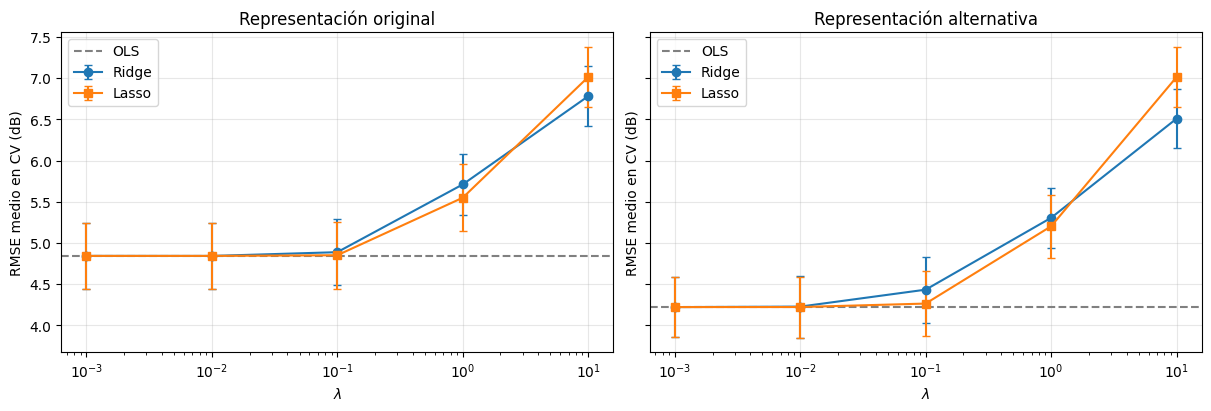

Referencia constante: RMSE medio = 7.014 dB


In [11]:
# RMSE medio frente a lambda (barras: desviación entre pliegues, no un intervalo de confianza).
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for a, rep in zip(ax, ("original", "alternativa")):
    for nombre, marca in (("Ridge", "o-"), ("Lasso", "s-")):
        t = resumen_cv.query("representacion == @rep and modelo == @nombre")
        a.errorbar(t["lambda"], t["RMSE_medio"], yerr=t["RMSE_desv"], fmt=marca, capsize=3, label=nombre)
    ols = resumen_cv.query("representacion == @rep and modelo == 'OLS'").iloc[0]
    a.axhline(ols["RMSE_medio"], color="gray", ls="--", label="OLS")
    a.set(xscale="log", xlabel=r"$\lambda$", ylabel="RMSE medio en CV (dB)", title=f"Representación {rep}")
    a.legend()
plt.show()
print("Referencia constante: RMSE medio =", round(resumen_cv.iloc[0]["RMSE_medio"], 3), "dB")

**Interpretación.** 

- **Referencia.** La referencia constante tiene RMSE medio de 7.01 dB.
- **Representación original.** OLS baja el RMSE a 4.84 dB.
- **Representación alternativa.** Con las dos variables de Strouhal, OLS baja a 4.22 dB, una mejora de 0.62 dB. La mejora es consistente: la representación alternativa gana en los 5 pliegues, con diferencias entre 0.42 y 0.82 dB, aunque la desviación entre pliegues (~0.37 dB) es del mismo orden.
- **Regularización.** No mejora a OLS de forma apreciable en ninguna representación. Con $\lambda\le10^{-2}$, Ridge y Lasso quedan a menos de 0.01 dB de OLS. Desde $\lambda=0.1$ el error crece, y con $\lambda_1=10$ Lasso anula todos los coeficientes y reproduce la referencia. Esto es esperable: hay 960 filas de entrenamiento por pliegue para 5 a 7 coeficientes, así que la varianza de OLS ya es pequeña y la regularización solo agrega sesgo.
- **Selección.** Tres candidatos de la representación alternativa quedan dentro de la tolerancia de empate de 0.001 dB: Ridge con $10^{-3}$, Lasso con $10^{-3}$ y Lasso con $10^{-2}$. La regla predefinida (mayor $\lambda$) elige **Lasso con $\lambda_1=0.01$**. La representación alternativa queda congelada también para OLS.

## 6c. Evaluación final en prueba

La representación y los hiperparámetros quedan congelados. Los finalistas son:

- la referencia constante;
- OLS;
- el candidato regularizado seleccionado.

Se ajustan una vez sobre todo el conjunto de desarrollo, con el escalador ajustado en desarrollo, y se evalúan **una sola vez** en prueba.

**Segmentos.** Se definen con desarrollo: frecuencia baja si `frecuencia` $\le$ mediana de desarrollo, y alta en caso contrario. El umbral se calcula sin mirar prueba.

In [12]:
X_des = representacion(desarrollo, REP).to_numpy()
X_pru = representacion(prueba, REP).to_numpy()
y_pru = prueba[OBJETIVO].to_numpy()

escalador = StandardScaler().fit(X_des)                    # estadísticas solo de desarrollo
crear_regularizado = RegresionRidge if elegido["modelo"] == "Ridge" else LassoProximal
finalistas = {
    "OLS": RegresionOLS().fit(escalador.transform(X_des), y_des),
    f"{elegido['modelo']} (lambda={elegido['lambda']:g})":
        crear_regularizado(float(elegido["lambda"])).fit(escalador.transform(X_des), y_des),
}
for nombre, modelo in finalistas.items():
    modelo.guardar_parametros(PARAMETROS / f"p6_{nombre.split()[0]}.json")

# --- Única evaluación en prueba ---
predicciones = {"Referencia (media)": np.full(len(y_pru), y_des.mean())}
predicciones.update({nombre: m.predict(escalador.transform(X_pru)) for nombre, m in finalistas.items()})

filas = []
for nombre, pred in predicciones.items():
    pred_mae = np.full(len(y_pru), np.median(y_des)) if nombre.startswith("Referencia") else pred
    filas.append({"modelo": nombre, "MAE": mean_absolute_error(y_pru, pred_mae),
                  "RMSE": rmse(y_pru, pred), "R2": r2_score(y_pru, pred)})
evaluacion = pd.DataFrame(filas).set_index("modelo")
evaluacion.to_csv(RESULTADOS / "p6_evaluacion_final.csv")

salida = prueba[["id", OBJETIVO]].rename(columns={OBJETIVO: "sonido_observado"})
for nombre, pred in predicciones.items():
    salida[f"pred_{nombre.split()[0]}"] = pred
salida.to_csv(RESULTADOS / "p6_predicciones_prueba.csv", index=False)

print("La referencia usa la media de desarrollo para RMSE y R2, y la mediana para MAE.")
evaluacion

La referencia usa la media de desarrollo para RMSE y R2, y la mediana para MAE.


,MAE,RMSE,R2
modelo,,,
Referencia (media),5.2047,6.3957,-0.0029
OLS,3.2463,4.1147,0.5849
Lasso (lambda=0.01),3.2448,4.1135,0.5851


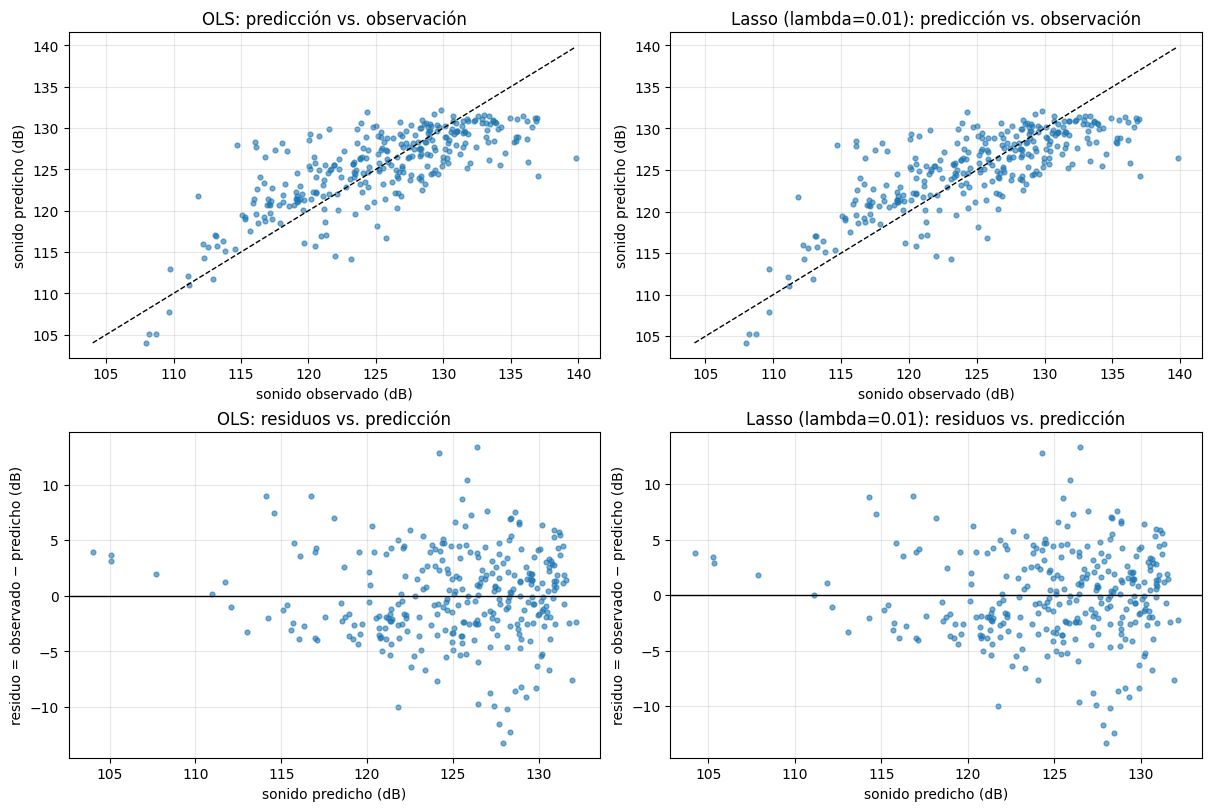

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for j, (nombre, modelo) in enumerate(finalistas.items()):
    pred = predicciones[nombre]
    residuo = y_pru - pred
    ax[0, j].scatter(y_pru, pred, s=12, alpha=0.6)
    lims = [min(y_pru.min(), pred.min()), max(y_pru.max(), pred.max())]
    ax[0, j].plot(lims, lims, "k--", lw=1)
    ax[0, j].set(xlabel="sonido observado (dB)", ylabel="sonido predicho (dB)", title=f"{nombre}: predicción vs. observación")
    ax[1, j].scatter(pred, residuo, s=12, alpha=0.6)
    ax[1, j].axhline(0, color="black", lw=1)
    ax[1, j].set(xlabel="sonido predicho (dB)", ylabel="residuo = observado − predicho (dB)",
                 title=f"{nombre}: residuos vs. predicción")
plt.show()

In [14]:
# Errores por segmento de frecuencia (umbral calculado con desarrollo).
umbral_frec = desarrollo["frecuencia"].median()
segmento = np.where(prueba["frecuencia"] <= umbral_frec, f"baja (<= {umbral_frec:g} Hz)", f"alta (> {umbral_frec:g} Hz)")
filas = []
for nombre in finalistas:
    for seg in np.unique(segmento):
        m = segmento == seg
        residuo = y_pru[m] - predicciones[nombre][m]
        filas.append({"modelo": nombre, "segmento": seg, "n": int(m.sum()),
                      "MAE": np.mean(np.abs(residuo)), "RMSE": np.sqrt(np.mean(residuo ** 2)),
                      "residuo medio": residuo.mean()})
por_segmento = pd.DataFrame(filas)
por_segmento.round(3)

,modelo,segmento,n,MAE,RMSE,residuo medio
0,OLS,alta (> 1600 Hz),155,3.019,3.686,-0.311
1,OLS,baja (<= 1600 Hz),146,3.488,4.526,0.184
2,Lasso (lambda=0.01),alta (> 1600 Hz),155,3.006,3.670,-0.300
3,Lasso (lambda=0.01),baja (<= 1600 Hz),146,3.499,4.538,0.175


**Interpretación.** 

**Métricas en prueba.**

- OLS (RMSE 4.11 dB, MAE 3.25 dB, $R^2=0.585$) y Lasso con $\lambda_1=0.01$ (4.11 dB, 3.24 dB, 0.585) son prácticamente idénticos. Esto es coherente con la validación cruzada, donde la diferencia fue menor que 0.001 dB.
- Ambos reducen el RMSE de la referencia (6.40 dB) en un 36 %. El RMSE de prueba (4.11) es algo menor que el medio de la CV (4.22), pero está dentro de la variación observada entre pliegues (3.79 a 4.66), así que no hay señal de sobreajuste en la selección.

**Errores sistemáticos.**

- En la gráfica de predicción frente a observación, los puntos forman una nube más plana que la diagonal. Los sonidos altos (observados > 133 dB) se subestiman, y los bajos (115–120 dB) tienden a sobreestimarse. El modelo comprime el rango de la respuesta.
- Los residuos negativos grandes (hasta −13 dB) se concentran en predicciones de 125–130 dB. Ahí el modelo predice un nivel medio-alto en condiciones que en realidad son más silenciosas.
- Ese patrón indica estructura no lineal que las dos variables de Strouhal no capturan, por ejemplo interacciones con el ángulo de ataque o con la cuerda.

**Errores por segmento.**

- El error es mayor en frecuencias bajas ($\le 1600$ Hz, $n=146$): RMSE 4.53 dB, frente a 3.69 dB en frecuencias altas ($n=155$).
- El residuo medio es positivo en bajas frecuencias (+0.18 dB, subestimación) y negativo en altas (−0.31 dB, sobreestimación).
- Esto coincide con el EDA: en frecuencias bajas el sonido tiene mayor dispersión para una misma frecuencia.

**Limitaciones.** Es un modelo lineal con 7 coeficientes y $R^2\approx0.59$: deja sin explicar cerca del 40 % de la variabilidad. Estos resultados se reportan sin reajustar ningún modelo.

## 6d. Alcance de la evaluación y elección del modelo

**¿Qué escenario de generalización representa la partición aleatoria?** Cada fila es un ensayo: una combinación de cuerda, velocidad, ángulo y frecuencia medida en el túnel de viento. Al partir las filas al azar, cada condición de prueba tiene "vecinas" en desarrollo: la misma cuerda, velocidad y ángulo, a otra frecuencia del mismo espectro. La evaluación mide, por lo tanto, la capacidad de **interpolar dentro de las configuraciones experimentales ya ensayadas**, por ejemplo completar frecuencias no medidas de un espectro conocido. No mide la capacidad de predecir configuraciones nuevas.

**¿Cómo evaluar condiciones experimentales nuevas?** Habría que partir por grupos de configuración, no por filas. Por ejemplo, con `GroupKFold` por la combinación (cuerda, velocidad, ángulo), de modo que todo el espectro de una configuración quede en prueba. Un caso más exigente es dejar fuera un nivel completo de una variable, como una cuerda o la velocidad más alta, para medir extrapolación. Esperaríamos errores mayores que los reportados aquí. La evaluación realizada **no** demuestra esa capacidad.

**¿Qué evidencia respalda la elección entre OLS, Ridge y Lasso?**

- En la validación cruzada, los tres modelos con $\lambda\le10^{-2}$ difieren en menos de 0.01 dB de RMSE medio, una diferencia mucho menor que la desviación entre pliegues (~0.37 dB). Los datos no permiten preferir un modelo por desempeño.
- Lasso con $\lambda_1=0.01$ se eligió por la regla de desempate fijada antes de comparar (mayor $\lambda$), no porque haya mostrado una ventaja. En prueba confirma el empate con OLS (4.1135 frente a 4.1147 dB).
- Con 1202 filas y 7 coeficientes, OLS es estable, y la regularización solo empeora el error cuando $\lambda$ crece.
- Lo que sí está respaldado por la evidencia es la **representación**: las variables de Strouhal reducen el RMSE en unos 0.6 dB, de forma consistente en los 5 pliegues.

Los coeficientes describen asociaciones en estos ensayos, no efectos causales. Por ejemplo, el peso de $\log_{10}St$ no significa que modificar una de sus componentes, manteniendo las demás fijas, produzca ese cambio en el sonido. Las variables están correlacionadas entre sí (ángulo y espesor, $r=0.75$), y el diseño experimental no las varía de forma independiente.